# Tugas 1 - Klasifikasi Wine Quality dengan KNN
  
| Nama              | NRP        |
|-------------------|------------|
| Rasya Gonawi      |5054251032         |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Wine Quality Dataset. Dataset bisa diakses melalui link berikut:\
🔗 https://www.kaggle.com/datasets/yasserh/wine-quality-dataset

Tujuan utama dari tugas ini adalah membangun model K-Nearest Neighbors (KNN) untuk mengklasifikasikan kualitas wine. 

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset & Eksplorasi Awal

- Memuat dataset, melihat struktur data, dan distribusi label.

2. Preprocessing 
- Memproses data agar siap untuk digunakan dalam membangun model.

3. Eksperimen Model KNN
- Bangun model KNN dengan mencoba beberapa nilai k (misalnya 3, 5, dan 7 --> BEBAS) serta dua metric jarak (seperti Euclidean dan Manhattan).
- Eksperimen ini bertujuan untuk membandingkan performa KNN dengan parameter yang berbeda.

4. Evaluasi Model
- Hitung metrik evaluasi seperti Accuracy, Precision, Recall, F1-Score, serta visualisasikan Confusion Matrix.

5. Analisis & Kesimpulan
- Bandingkan hasil antar eksperimen yang telah dilakukan dan berikan kesimpulan.


# 1. Persiapan Dataset & Eksplorasi Awal

In [3]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import seaborn as sns


In [4]:
#  Load Dataset dan menampilkan informasi dasar tentang dataset, seperti jumlah baris dan kolom, tipe data, jumlah nilai yang hilang, dan informasi lainnya yang dibutuhkan.


data = pd.read_csv('dataset/WineQT.csv')
data.info()
data.describe()
data.head()
data = data.drop("Id", axis=1)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [5]:
print(data.shape)
print(data.isnull().sum())
print(data.duplicated().sum())

print(f"dimensi :{data['quality'].value_counts(normalize=True)}")


(1143, 12)
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
125
dimensi :quality
5    0.422572
6    0.404199
7    0.125109
4    0.028871
8    0.013998
3    0.005249
Name: proportion, dtype: float64


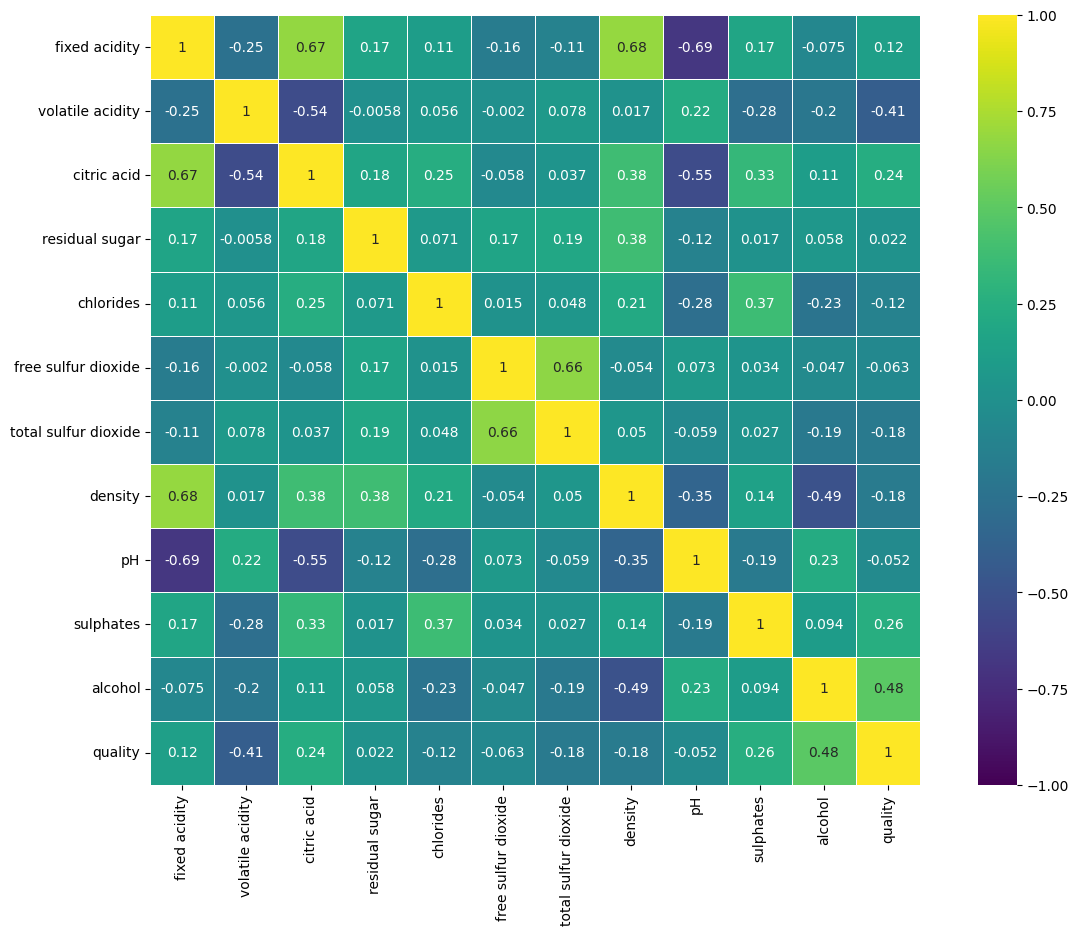

In [6]:
#correlation matrix
correlation_matrix = data.corr()
plt.figure(figsize=(15,10))
sns.heatmap(correlation_matrix, cmap = 'viridis',annot = True,square = True, vmin = -1,vmax = 1, center = 0, linewidth =.5)
plt.show()


C:\Users\ASUS\AppData\Local\Temp\ipykernel_4488\2042124175.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='quality', data=data, palette='viridis')


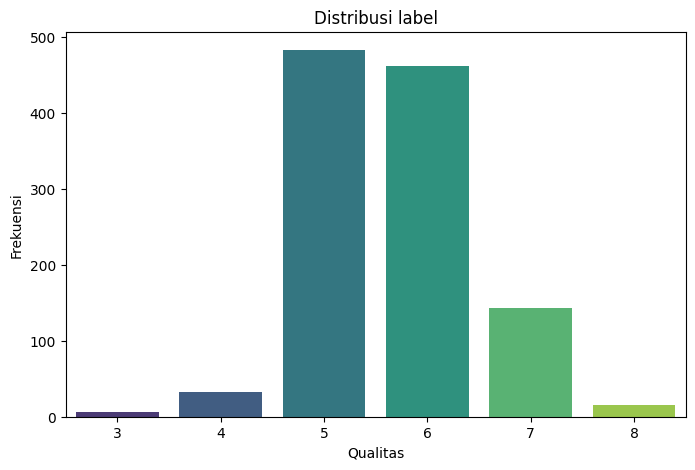

In [ ]:
# Tampilkan distribusi label (quality) dalam bentuk visualisasi, misalnya menggunakan histogram atau bar plot.

plt.figure(figsize=(8, 5))
sns.countplot(x='quality', data=data, palette='viridis')
plt.title('Distribusi label')
plt.xlabel('Qualitas')
plt.ylabel('Frekuensi')
plt.show()


## Silahkan Lakukan Exploratory Data Analysis (EDA) tambahan yang dibutuhkan. 

# 2. Preprocessing




In [ ]:
# NaN handling (drop, impute, etc.), duplicate handling, dan lain-lain.

#buang data duplicated, ada 125
print(data.duplicated().value_counts())

data = data.drop_duplicates()

print(data.duplicated().sum())

False    1018
Name: count, dtype: int64
0


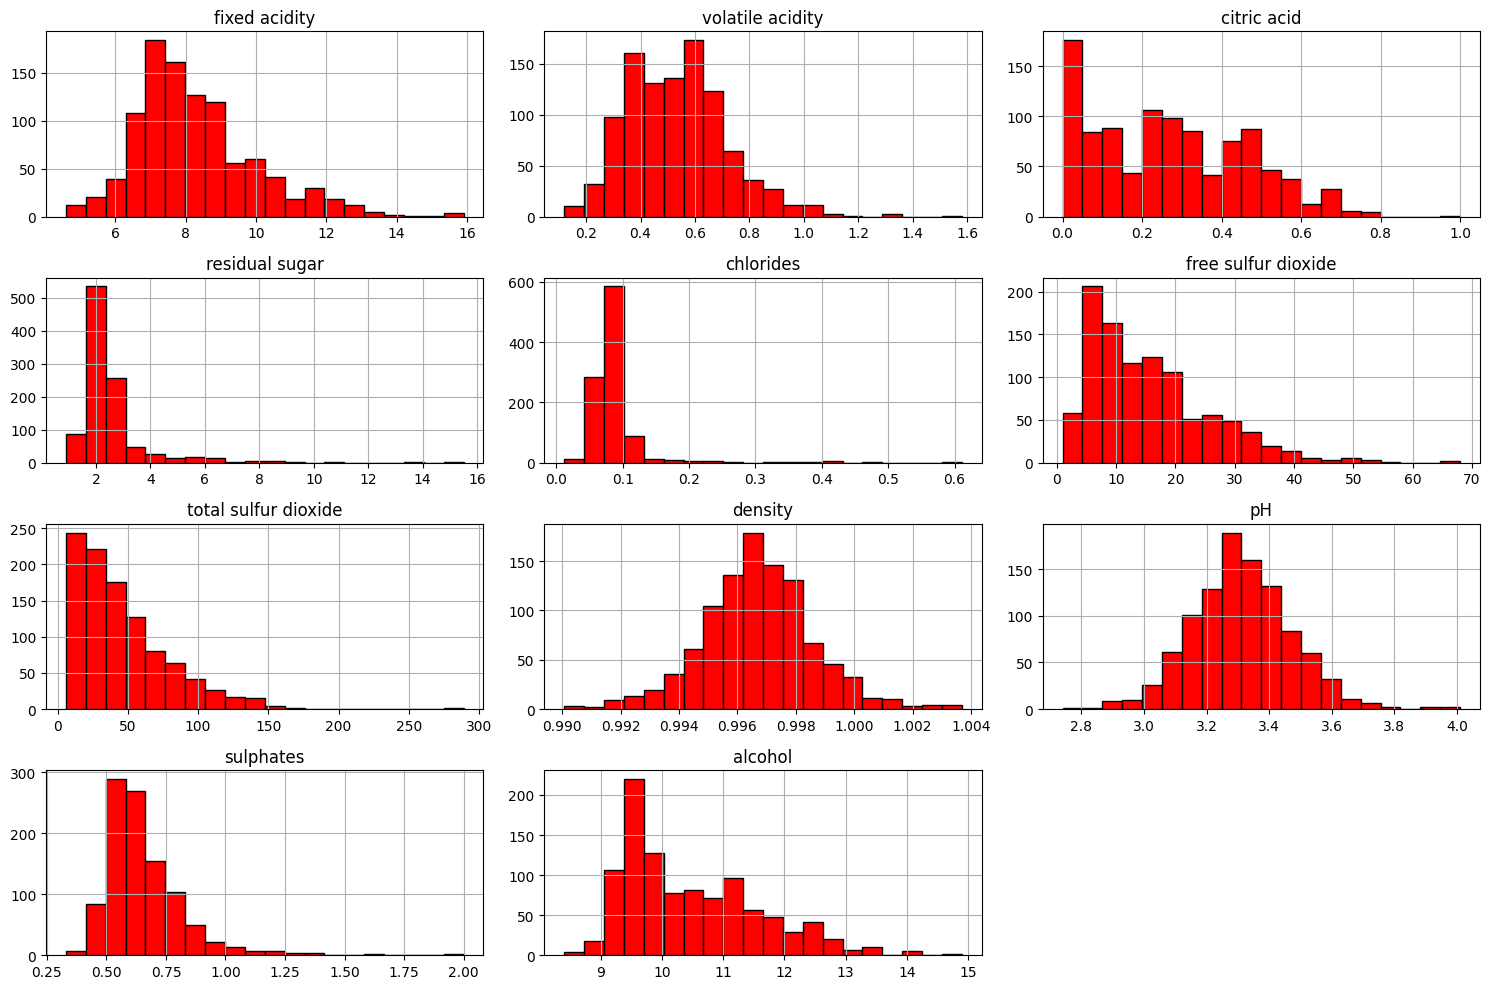

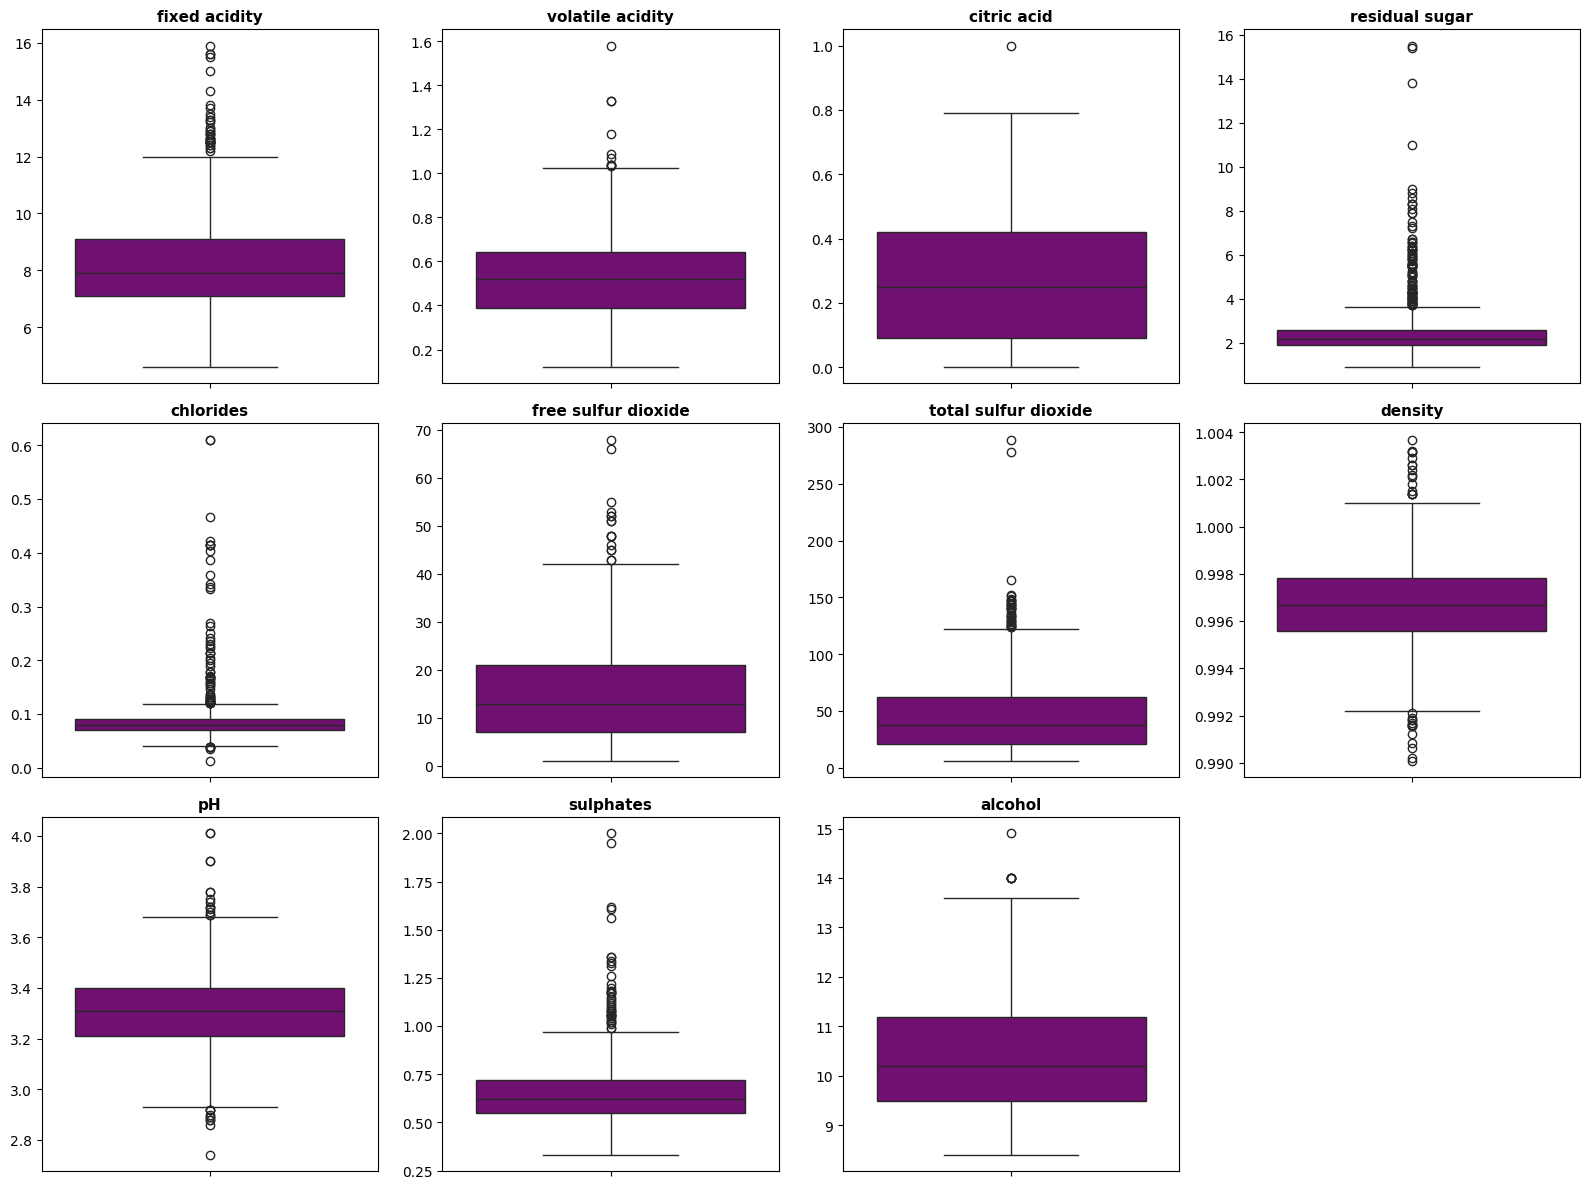

In [ ]:
# Periksa Outliers (jika diperlukan), misalnya menggunakan boxplot atau metode statistik lainnya. (Bisa dilakukan eksperimen dengan dan tanpa outlier untuk melihat perbedaan performa model)#Data Distribution
data.drop("quality", axis = 1).hist(bins=20, figsize=(15,10), color='red',edgecolor="black")
plt.tight_layout()
plt.show()



fitur = data.drop([ 'quality'], axis=1)
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 12))
axes = axes.flatten() 

for i, col in enumerate(fitur.columns):
    sns.boxplot(y=fitur[col], ax=axes[i], color='purple')
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_ylabel('')

fig.delaxes(axes[11])

plt.tight_layout()
plt.show()

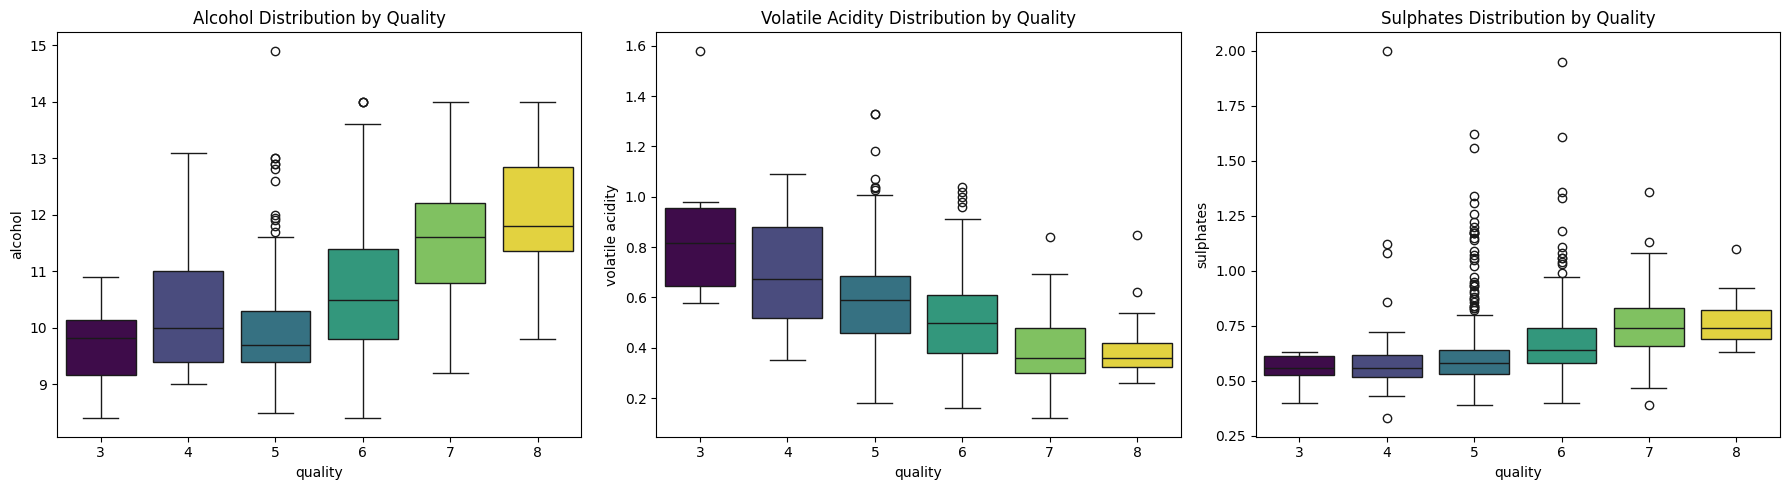

Aggregated Statistics Grouped by Quality:
            alcohol         volatile acidity         chlorides          \
              mean  median             mean  median      mean  median   
quality                                                                 
3         9.691667   9.825         0.897500  0.8175  0.105333  0.0800   
4        10.260606  10.000         0.700000  0.6750  0.094788  0.0780   
5         9.912702   9.700         0.587436  0.5900  0.091880  0.0820   
6        10.669030  10.500         0.504731  0.5000  0.085687  0.0780   
7        11.541120  11.600         0.390615  0.3600  0.074697  0.0705   
8        12.000000  11.800         0.414000  0.3600  0.070200  0.0720   

        residual sugar         
                  mean median  
quality                        
3             2.666667    2.1  
4             2.566667    2.1  
5             2.527252    2.2  
6             2.444010    2.2  
7             2.750410    2.3  
8             2.646667    2.0  


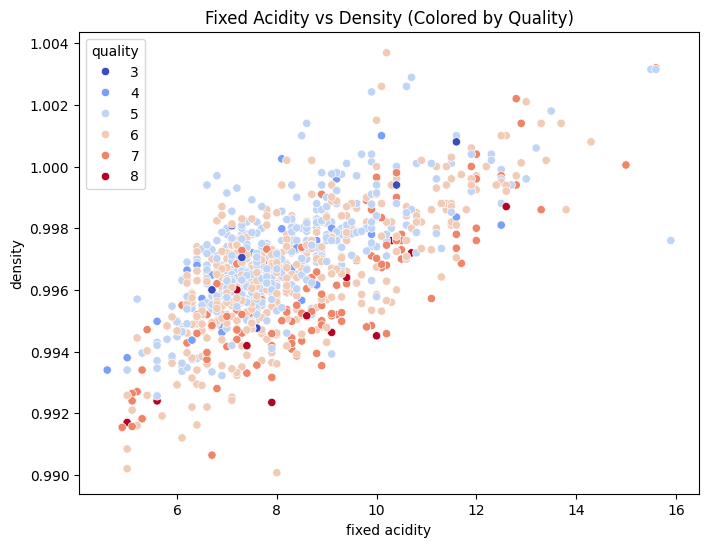

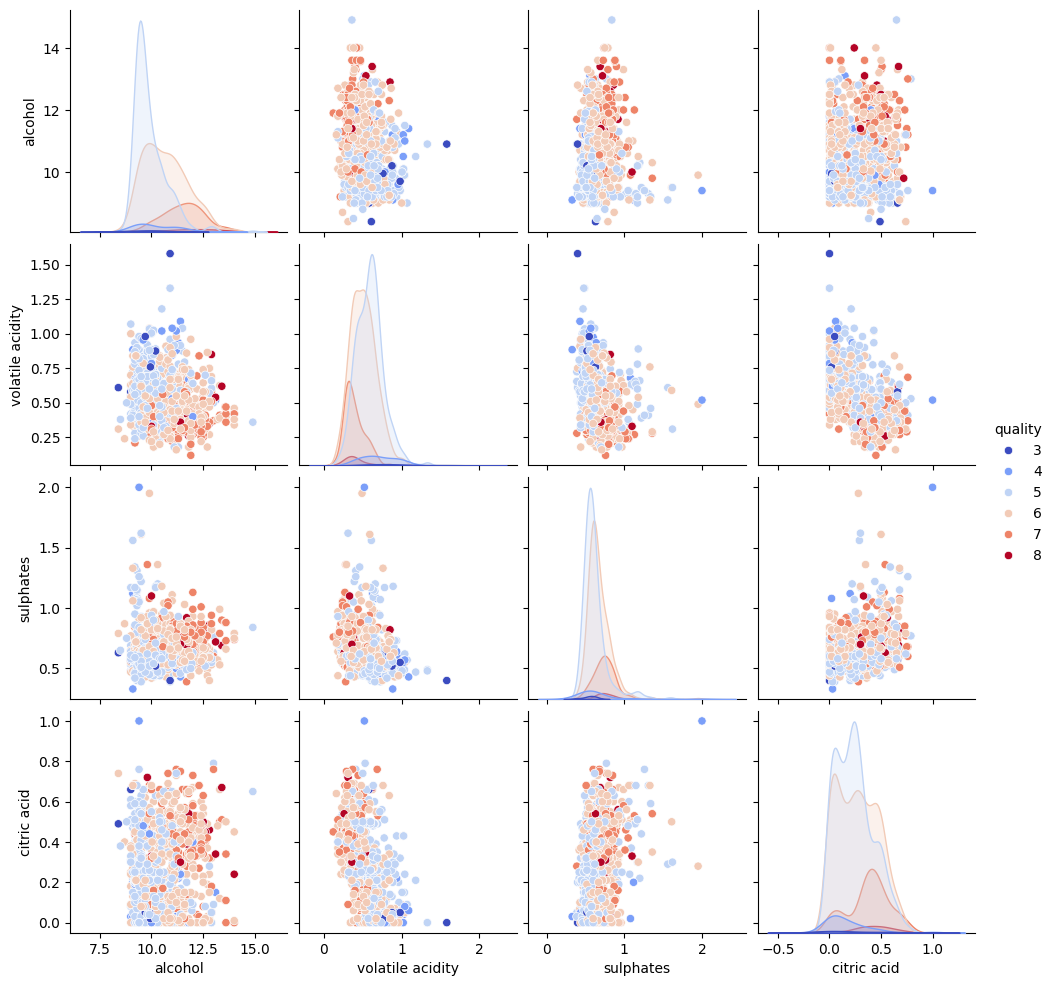


Quality distribution of Residual Sugar outliers (> 8.07):
quality
5    3
6    6
7    2
Name: count, dtype: int64

Quality distribution of Chlorides outliers (> 0.36):
quality
4    1
5    7
6    2
7    1
Name: count, dtype: int64


In [19]:


# 2. Target-Segmented Distributions (Boxplots)
# 2. Target-Segmented Distributions (Boxplots)
top_features = ['alcohol', 'volatile acidity', 'sulphates']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, feature in enumerate(top_features):
    # Added hue='quality' and legend=False to comply with Seaborn v0.14.0+
    sns.boxplot(x='quality', y=feature, data=data, ax=axes[i], hue='quality', palette='viridis', legend=False)
    axes[i].set_title(f'{feature.title()} Distribution by Quality')
plt.tight_layout()
plt.show()

# Analyze shifting trends across classes
quality_stats = data.groupby('quality').agg(['mean', 'median'])[[
    'alcohol', 'volatile acidity', 'chlorides', 'residual sugar'
]]
print("Aggregated Statistics Grouped by Quality:\n", quality_stats)

# 3. Multivariate Interaction Analysis
plt.figure(figsize=(8, 6))
sns.scatterplot(x='fixed acidity', y='density', hue='quality', palette='coolwarm', data=data)
plt.title('Fixed Acidity vs Density (Colored by Quality)')
plt.show()

# Pairplot for non-linear relationships among top predictors
sns.pairplot(data[['quality', 'alcohol', 'volatile acidity', 'sulphates', 'citric acid']], hue='quality', palette='coolwarm')
plt.show()

# 4. Contextual Outlier Investigation
# Isolate the top 1% of extreme values
sugar_threshold = data['residual sugar'].quantile(0.99)
chlorides_threshold = data['chlorides'].quantile(0.99)

sugar_outliers = data[data['residual sugar'] > sugar_threshold]
chlorides_outliers = data[data['chlorides'] > chlorides_threshold]

print(f"\nQuality distribution of Residual Sugar outliers (> {sugar_threshold:.2f}):")
print(sugar_outliers['quality'].value_counts().sort_index())

print(f"\nQuality distribution of Chlorides outliers (> {chlorides_threshold:.2f}):")
print(chlorides_outliers['quality'].value_counts().sort_index())

In [32]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from imblearn.over_sampling import SMOTE

X = data.drop(columns=['quality'])
y = data['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Distribusi Kelas (Sebelum SMOTE):\n", y_train.value_counts().sort_index())





Distribusi Kelas (Sebelum SMOTE):
 quality
3      5
4     26
5    346
6    327
7     98
8     12
Name: count, dtype: int64


In [33]:
#scaling menggunakan robustscaler

scaler = RobustScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

smote = SMOTE(random_state=42, k_neighbors=3)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("\nDistribusi Kelas (Setelah SMOTE):\n", y_train_resampled.value_counts().sort_index())


Distribusi Kelas (Setelah SMOTE):
 quality
3    346
4    346
5    346
6    346
7    346
8    346
Name: count, dtype: int64


# 3. Eksperimen Model KNN


Classification Report KNN:

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.04      0.14      0.07         7
           5       0.68      0.51      0.58        87
           6       0.48      0.28      0.35        82
           7       0.35      0.62      0.45        24
           8       0.00      0.00      0.00         3

    accuracy                           0.41       204
   macro avg       0.26      0.26      0.24       204
weighted avg       0.52      0.41      0.44       204



Text(0.5, 36.72222222222221, 'Label Prediksi')

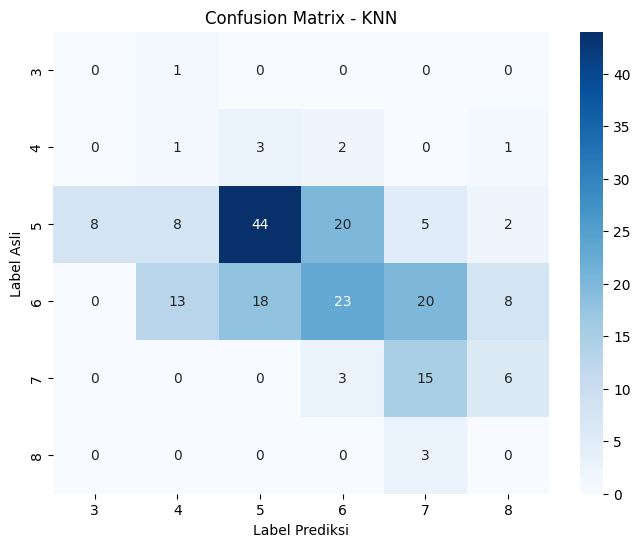

In [34]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix


knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_resampled, y_train_resampled)

y_pred = knn.predict(X_test_scaled)

print("Classification Report KNN:\n")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=sorted(y_test.unique()), 
            yticklabels=sorted(y_test.unique()))
plt.title('Confusion Matrix - KNN')
plt.ylabel('Label Asli')
plt.xlabel('Label Prediksi')

In [41]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

X = data.drop(columns=[ 'quality'])
y = data['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Inisialisasi Objek Global
smote = SMOTE(random_state=42, k_neighbors=3)
knn = KNeighborsClassifier(n_neighbors=5)

EKSPERIMEN 

In [37]:
#tanpa scaling

# SMOTE langsung pada data asli
X_train_res_unscaled, y_train_res_unscaled = smote.fit_resample(X_train, y_train)

# Training & Prediksi
knn.fit(X_train_res_unscaled, y_train_res_unscaled)
y_pred_unscaled = knn.predict(X_test)

print("=== Hasil KNN (Tanpa Scaling) ===")
print(classification_report(y_test, y_pred_unscaled, zero_division=0))

=== Hasil KNN (Tanpa Scaling) ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.55      0.39      0.46        87
           6       0.39      0.18      0.25        82
           7       0.12      0.21      0.15        24
           8       0.00      0.00      0.00         3

    accuracy                           0.26       204
   macro avg       0.18      0.13      0.14       204
weighted avg       0.41      0.26      0.31       204



In [42]:
# Scaling dengan MinMax
minmax = MinMaxScaler()
X_train_minmax = pd.DataFrame(minmax.fit_transform(X_train), columns=X.columns)
X_test_minmax = pd.DataFrame(minmax.transform(X_test), columns=X.columns)

# SMOTE pada data MinMax
X_train_res_minmax, y_train_res_minmax = smote.fit_resample(X_train_minmax, y_train)

# Training & Prediksi
knn.fit(X_train_res_minmax, y_train_res_minmax)
y_pred_minmax = knn.predict(X_test_minmax)

print("=== Hasil KNN (MinMaxScaler) ===")
print(classification_report(y_test, y_pred_minmax, zero_division=0))

=== Hasil KNN (MinMaxScaler) ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.04      0.14      0.06         7
           5       0.67      0.46      0.54        87
           6       0.49      0.32      0.39        82
           7       0.33      0.58      0.42        24
           8       0.00      0.00      0.00         3

    accuracy                           0.40       204
   macro avg       0.25      0.25      0.23       204
weighted avg       0.52      0.40      0.44       204



In [43]:
# Scaling dengan Standard
std = StandardScaler()
X_train_std = pd.DataFrame(std.fit_transform(X_train), columns=X.columns)
X_test_std = pd.DataFrame(std.transform(X_test), columns=X.columns)

# SMOTE pada data Standard
X_train_res_std, y_train_res_std = smote.fit_resample(X_train_std, y_train)

# Training & Prediksi
knn.fit(X_train_res_std, y_train_res_std)
y_pred_std = knn.predict(X_test_std)

print("=== Hasil KNN (StandardScaler) ===")
print(classification_report(y_test, y_pred_std, zero_division=0))

=== Hasil KNN (StandardScaler) ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.04      0.14      0.06         7
           5       0.66      0.43      0.52        87
           6       0.49      0.37      0.42        82
           7       0.29      0.42      0.34        24
           8       0.00      0.00      0.00         3

    accuracy                           0.38       204
   macro avg       0.25      0.23      0.22       204
weighted avg       0.51      0.38      0.43       204



In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report


X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)


smote = SMOTE(random_state=42, k_neighbors=3)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

#Parameter Eksperimen
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'], 
    'metric': ['euclidean', 'manhattan', 'chebyshev']
}

#Grid Search CV untuk mencari kombinasi terbaik
knn = KNeighborsClassifier()
grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
grid_search.fit(X_train_res, y_train_res)

# Hasil Terbaik
print("Kombinasi Parameter Terbaik:", grid_search.best_params_)

# 7. Evaluasi Model Terbaik pada Data Uji
best_knn = grid_search.best_estimator_
y_pred_best = best_knn.predict(X_test_scaled)
print("\nClassification Report (Model Terbaik):\n")
print(classification_report(y_test, y_pred_best))

Kombinasi Parameter Terbaik: {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'distance'}

Classification Report (Model Terbaik):

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.05      0.14      0.07         7
           5       0.70      0.52      0.60        87
           6       0.51      0.35      0.42        82
           7       0.30      0.54      0.38        24
           8       0.00      0.00      0.00         3

    accuracy                           0.43       204
   macro avg       0.26      0.26      0.24       204
weighted avg       0.54      0.43      0.47       204



# 5. Analisis

untuk modelling data nya, disini saya melakukan beberapa tahapan dan eksperimen

1. Train-Test Split dengan stratifikasi: dataset dibagi dengan rasio 80:20 menggunakan parameter stratify=y guna memastikan proporsi kelas minoritas yang sangat sedikit tetap terdistribusi adil di data latih dan data uji, bisa kita liat kelas 3,4,8 sangat ketimpangan dengan kelas kelas yang lain.

2. Scaling dengan beberapa eksperimen seperti:

tanpa Scaling: Gagal karena algoritma KNN buta terhadap fitur berangka kecil dan menunjukkan degradasi performa yang parah. Model gagal  mengenali kelas 4 (recall 0.00) dan mengalami penurunan drastis pada kelas-kelas lainnya. Hal ini membuktikan bahwa algoritma KNN yang mengandalkan jarak spasial (Euclidean distance) menjadi buta ketika fitur-fitur berangka kecil tertelan oleh fitur dengan magnitudo besar seperti total sulfur dioxide.

MinMaxScaler: Memberikan hasil yang cukup mendekati RobustScaler. namun pemetaan nilai ke rentang 0 hingga 1 membuat sebagian besar data normal terkompresi secara rapat karena adanya outlier ekstrem, sehingga batas antar tetangga terdekat menjadi kurang optimal untuk kelas minoritas.

StandardScaler: Performa berada di bawah RobustScaler dan MinMaxScaler. Standarisasi berbasis rata-rata dan standar deviasi sangat rentan terhadap tarikan outlier, menyebabkan titik pusat data bergeser dan menurunkan ketepatan kalkulasi jarak KNN.

RobustScaler : Menggunakan median dan Interquartile Range (IQR), menjadikannya metode terbaik untuk meredam dampak outlier ekstrem pada residual sugar dan chlorides tanpa merusak struktur data aslinya. Menghasilkan keseimbangan terbaik di antara metode scaling lainnya. Model mampu mendeteksi kelas 7 dengan recall mencapai 0.62 (artinya 62% data kelas 7 berhasil dikenali dengan benar). Penggunaan median dan rentang interkuartil (IQR) terbukti efektif meredam distorsi dari pencilan (outlier) ekstrem seperti pada fitur residual sugar dan chlorides. lalu menggunakan GridSearchCV untuk mencari kemungkinan parameter terbaik yang dimana menghasilkan sedikit peningkatan

3. Penanganan Imbalance Data : karena data labelnya sangat imbalance, disini saya menerapkan SMOTE dan hanya diterapkan hanya pada data latih untuk menyintesis sampel data baru pada kelas minoritas (skor 3, 4, 7, dan 8) dan mencegah model mengalami bias ke kelas mayoritas (5 dan 6).

4. Pemodelan Machine Learning (K-Nearest Neighbors / KNN)
Algoritma KNN diuji melalui berbagai skenario eksperimen untuk melihat performa prediksinya:

Analisis hasil evaluasi KNN dari seluruh skenario scaling menunjukkan bahwa performa model sangat dipengaruhi oleh cara algoritma mengukur jarak spasial antar titik data. Tanpa adanya scaling, akurasi model anjlok drastis ke angka 26% dan gagal total mengenali kelas minoritas karena fitur dengan magnitudo besar seperti total sulfur dioxide mendominasi perhitungan jarak Euclidean. Ketika MinMaxScaler dan StandardScaler diterapkan, akurasi meningkat ke kisaran 38–40%, namun masih terbatas karena kerentanan terhadap outlier ekstrem yang merusak titik pusat data. Penggunaan RobustScaler memberikan hasil yang lebih baik dengan akurasi 41%, karena pemanfaatan median dan IQR mampu meredam distorsi outlier pada fitur seperti residual sugar dan chlorides. namun, seluruh varian model KNN secara konsisten masih kesulitan memprediksi kelas ekstrem (skor 3, 4, dan 8) karena jumlah sampel aslinya yang sangat minim serta tingginya tumpang tindih fiturpada area kelas menengah.



# 6. Kesimpulan dan Saran

kesimpulan dari eksperimen yang saya dapatkan, dari saya melakukan scaling, preprocessing data, SMOTE, mencoba berbagai teknik scaling, namun pada akhirnya peningkatan hasilnya tidak signifikan (kecuali yang tanpa scaling, yang membuat hasilnya sangat jauh dari yang lain), yang saya  bisa ambil kesimpulan bahwa DATASET itu sangat mempengaruhi hasil, mau sebagus apapun teknik yang digunakan, jika data yang dimiliki itu dari awal sudah kurang baik, maka akan menghasilkan output yang kurang baik juga (garbage in garbage out)

bisa kita lihat dari distribusi data yang sangat ekstrim, dimana kelas 3,4, dan 8 sangat jauh dibandingkan kelas yang lainnya, sehingga walau sudah dilakukan SMOTE, hasilnya tidak cukup akurat, dan mungkin ada pengaruh dari model KNN yang digunakan juga karena hanya berfokus pada jarak

saran yang bisa saya sampaikan kedepannya kepada mba dan mas asdos, mungkin bisa lebih di spesifikasikan lagi pipeline data yang kami perlu lakukan, mungkin seperti Feature Engineering dll sehingga kami bisa lebih spesifik untuk melakukan analisis yang lebih akurat kedepannya, karena saya dan mungkin teman teman yang lain masih kesulitan untuk membuat workflow pipeline analisis data ini (untung ada ai yang membantu membuat strategi). but so far, W mas dan mba asdos, thank you!